In [1]:
!pip install -q ultralytics

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
LR range: 1e-05 -> 0.03
Maximum optimizer steps: 100
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_3class.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_

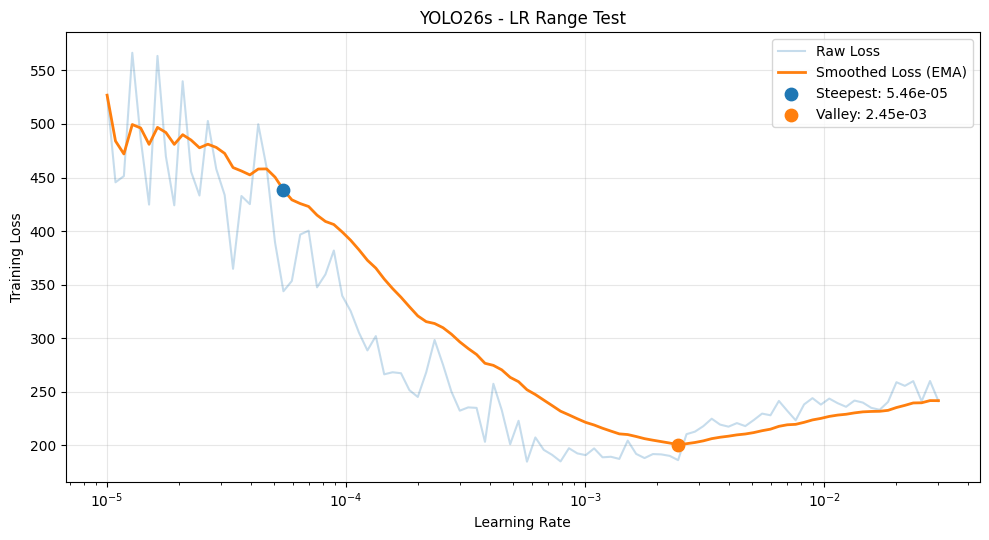


========== LR FINDER RESULT ==========
Optimizer steps : 100
Steepest LR     : 5.464761e-05
Valley LR       : 2.445264e-03

Saved CSV : /kaggle/working/lr_finder_yolo26s/lr_finder_step_results.csv
Saved PNG : /kaggle/working/lr_finder_yolo26s/lr_finder_step_curve.png


In [2]:

# ============================================================
# YOLO26s - LEARNING RATE FINDER
# RDD2022 | 3 classes | Kaggle
# ============================================================

import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml

from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionTrainer


# ============================================================
# 1. CAU HINH
# ============================================================

MODEL_NAME = "yolo26s.pt"

DATA_ROOT = Path(
    "/kaggle/input/datasets/vtmhhh/datakhuyen/RDD2022_L3_New"
)

DATA_YAML = Path("/kaggle/working/data_3class.yaml")
OUTPUT_DIR = Path("/kaggle/working/lr_finder_yolo26s")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LR_MIN = 1e-5
LR_MAX = 3e-2
MAX_STEPS = 100

TRAIN_FRACTION = 0.50
IMG_SIZE = 640
BATCH_SIZE = 64
WORKERS = 4
SEED = 42

EMA_BETA = 0.90
DIVERGENCE_FACTOR = 3.0
MIN_STEPS_BEFORE_STOP = 20

DEVICE = 0
assert torch.cuda.is_available(), "Hay bat GPU tren Kaggle."
assert DATA_ROOT.is_dir(), f"Khong tim thay dataset: {DATA_ROOT}"

print("GPU:", torch.cuda.get_device_name(0))
print(f"LR range: {LR_MIN} -> {LR_MAX}")
print(f"Maximum optimizer steps: {MAX_STEPS}")


# ============================================================
# 2. CHUAN BI DATASET
# ============================================================

data_config = {
    "path": str(DATA_ROOT),
    "train": [
        "Japan_RDD/train/images",
        "China_RDD/train/images",
        "India_RDD/train/images",
    ],
    "val": [
        "Japan_RDD/val/images",
        "China_RDD/val/images",
        "India_RDD/val/images",
    ],
    "test": [
        "Japan_RDD/test/images",
        "China_RDD/test/images",
        "India_RDD/test/images",
    ],
    "names": {
        0: "pothole",
        1: "linear_crack",
        2: "alligator_crack",
    },
}

for split in ("train", "val", "test"):
    for folder in data_config[split]:
        assert (DATA_ROOT / folder).is_dir(), (
            f"Thieu thu muc: {DATA_ROOT / folder}"
        )

with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        data_config, f,
        sort_keys=False,
        allow_unicode=True
    )


# ============================================================
# 3. CUSTOM TRAINER - LEARNING RATE RANGE TEST
# ============================================================

history = []

class LRRangeStop(Exception):
    """Dung phep quet LR co chu dich."""
    pass

class LRFinderTrainer(DetectionTrainer):

    def optimizer_step(self):

        # Khoi tao tai lan optimizer step dau tien
        if not hasattr(self, "lr_step"):
            self.lr_step = 0
            self.lr_loss_ema = None
            self.best_ema = float("inf")

            batches = len(self.train_loader)
            accumulate = max(1, int(self.accumulate))

            self.total_steps = min(
                MAX_STEPS,
                math.ceil(batches / accumulate)
            )
            print("So batch thuc te:", batches)
            print("Gradient accumulation:", accumulate)
            print("Optimizer steps du kien:", self.total_steps)
            

        # 3.1. Tinh LR theo cap so nhan
        t = self.lr_step
        lr = LR_MIN * (LR_MAX / LR_MIN) ** (t / max(self.total_steps - 1, 1))

        for group in self.optimizer.param_groups:
            group["lr"] = lr

        # 3.2. Lấy/đọc Training Loss
        loss = self.loss

        if isinstance(loss, torch.Tensor):
            loss = float(
                loss.detach().float().sum().cpu()
            )
        else:
            loss = float(loss)

        if not np.isfinite(loss):
            raise LRRangeStop("Loss la NaN hoac Inf.")

        # 3.3. Lam muot Loss bang EMA
        self.lr_loss_ema = (
        loss if self.lr_loss_ema is None
        else EMA_BETA * self.lr_loss_ema + (1 - EMA_BETA) * loss
        )
        self.best_ema = min(self.best_ema, self.lr_loss_ema)

        # 3.4. Dung neu Loss phan ky
        if (
            t >= MIN_STEPS_BEFORE_STOP
            and self.lr_loss_ema > DIVERGENCE_FACTOR * self.best_ema
        ):
            raise LRRangeStop(
                f"Loss phan ky tai LR = {lr:.3e}"
            )

        # 3.5. Cap nhat trong so bang AdamW
        old_scale = (
            float(self.scaler.get_scale())
            if self.scaler.is_enabled()
            else None
        )

        super().optimizer_step()

        new_scale = (
            float(self.scaler.get_scale())
            if self.scaler.is_enabled()
            else None
        )

        # Neu AMP bo qua update, khong tang bo dem
        if old_scale is not None and new_scale < old_scale:
            print(f"AMP skipped update: LR = {lr:.3e}")
            return

        # 3.6. Ghi nhan ket qua
        history.append({
            "optimizer_step": t + 1,
            "lr": lr,
            "loss": loss,
            "ema_loss": self.lr_loss_ema,
        })

        self.lr_step += 1

        if self.lr_step >= self.total_steps:
            raise LRRangeStop(
                "Hoan thanh LR Range Test."
            )


# ============================================================
# 4. CHAY LR FINDER
# ============================================================

model = YOLO(MODEL_NAME)

try:
    model.train(
        trainer=LRFinderTrainer,
        data=str(DATA_YAML),

        epochs=1,
        fraction=TRAIN_FRACTION,

        imgsz=IMG_SIZE,
        batch=BATCH_SIZE,
        workers=WORKERS,
        device=DEVICE,

        optimizer="AdamW",
        lr0=LR_MIN,
        lrf=1.0,
        cos_lr=False,
        warmup_epochs=0,
        close_mosaic=0,

        nbs=64,
        seed=SEED,
        deterministic=True,
        amp=True,

        val=False,
        save=False,
        plots=False,
        verbose=False,

        project=str(OUTPUT_DIR),
        name="range_test_step_based",
        exist_ok=True,
    )

except LRRangeStop as e:
    print("LR Finder stopped:", e)


# ============================================================
# 5. PHAN TICH KET QUA
# ============================================================

df = pd.DataFrame(history)

if len(df) < 15:
    raise RuntimeError(
        "Khong du optimizer steps de phan tich."
    )

csv_path = OUTPUT_DIR / "lr_finder_step_results.csv"
df.to_csv(csv_path, index=False)

lrs = df["lr"].to_numpy()
losses = df["loss"].to_numpy()

# EMA voi bias correction 
smooth = []
avg = 0.0

for i, loss in enumerate(losses, start=1):
    avg = EMA_BETA * avg + (1 - EMA_BETA) * loss
    smooth.append(avg / (1 - EMA_BETA ** i))

smooth = np.asarray(smooth)

# Valley: LR tai Loss nho nhat
valley_idx = int(np.argmin(smooth))

# Steepest: LR tai do doc giam manh nhat
skip = min(10, valley_idx // 2)

if valley_idx >= skip + 5:
    x = np.log10(lrs[skip:valley_idx + 1])
    y = smooth[skip:valley_idx + 1]

    slopes = np.gradient(y, x)
    steepest_idx = skip + int(np.argmin(slopes))
else:
    steepest_idx = valley_idx

steepest_lr = float(lrs[steepest_idx])
valley_lr = float(lrs[valley_idx])


# ============================================================
# 6. VE BIEU DO LR FINDER
# ============================================================

plt.figure(figsize=(10, 5.5))

plt.plot(
    lrs, losses,
    alpha=0.25,
    label="Raw Loss"
)

plt.plot(
    lrs, smooth,
    linewidth=2,
    label="Smoothed Loss (EMA)"
)

plt.scatter(
    steepest_lr,
    smooth[steepest_idx],
    s=80,
    zorder=5,
    label=f"Steepest: {steepest_lr:.2e}"
)

plt.scatter(
    valley_lr,
    smooth[valley_idx],
    s=80,
    zorder=5,
    label=f"Valley: {valley_lr:.2e}"
)

plt.xscale("log")
plt.xlabel("Learning Rate")
plt.ylabel("Training Loss")
plt.title("YOLO26s - LR Range Test")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plot_path = OUTPUT_DIR / "lr_finder_step_curve.png"

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. IN KET QUA
# ============================================================

print("\n========== LR FINDER RESULT ==========")
print(f"Optimizer steps : {len(df)}")
print(f"Steepest LR     : {steepest_lr:.6e}")
print(f"Valley LR       : {valley_lr:.6e}")

print("\nSaved CSV :", csv_path)
print("Saved PNG :", plot_path)

